# Facial Expression Classification with Geometric Features

Compare a decision tree, SVM, and PyTorch MLP on 25 corrected geometric features. This walkthrough displays the checked-in benchmark results. Set `RUN_BENCHMARK = True` to regenerate both runs from the installed package. See `../README.md` for setup.

**Evaluation scope:** inferred triples are a sensitivity analysis. Neither protocol verifies subject independence.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
from facial_expression.data import ROOT, load_data

RUN_BENCHMARK = False
print("Benchmark package ready")

Benchmark package ready


## Data and provenance

The corrected features are regenerated from the committed 468-point landmark exports. Original coursework data remain in the archive. Ratios retain their dimensionless units; lengths and symmetry offsets use eye-span units.

In [2]:
data = load_data(ROOT / "data/features.csv")
provenance = json.loads((ROOT / "data/provenance.json").read_text())
print(f"{len(data)} images, {data.shape[1] - 2} features; schema v{provenance["feature_schema_version"]}")
display(data.groupby("emotion").size().rename("images").to_frame())

981 images, 25 features; schema v2


,images
emotion,
anger,135
contempt,54
disgust,177
fear,75
happy,207
sadness,84
surprise,249


## Reproduce the experiments

Each classical search fits scaling and SMOTE inside training folds. The MLP is tuned and stopped on validation macro F1. Test predictions are made after selection. CPU runs are seeded; versions and dataset hashes are recorded.

In [3]:
if RUN_BENCHMARK:
    for command in [
        ["-m", "facial_expression.features"],
        ["-m", "facial_expression.train", "--output-dir", str(ROOT / "results")],
        ["-m", "facial_expression.train", "--split-strategy", "inferred-sequence", "--output-dir", str(ROOT / "results/inferred_sequence")],
        ["-m", "facial_expression.report"],
    ]:
        subprocess.run([sys.executable, *command], cwd=ROOT, check=True)
else:
    print("Displaying saved full benchmark outputs. Set RUN_BENCHMARK = True to rerun.")

Displaying saved full benchmark outputs. Set RUN_BENCHMARK = True to rerun.


protocol,Image split,Inferred groups
model,,
decision_tree,0.8105,0.4664
dummy,0.0584,0.0590
mlp,0.9632,0.6570
svm,0.9897,0.6230


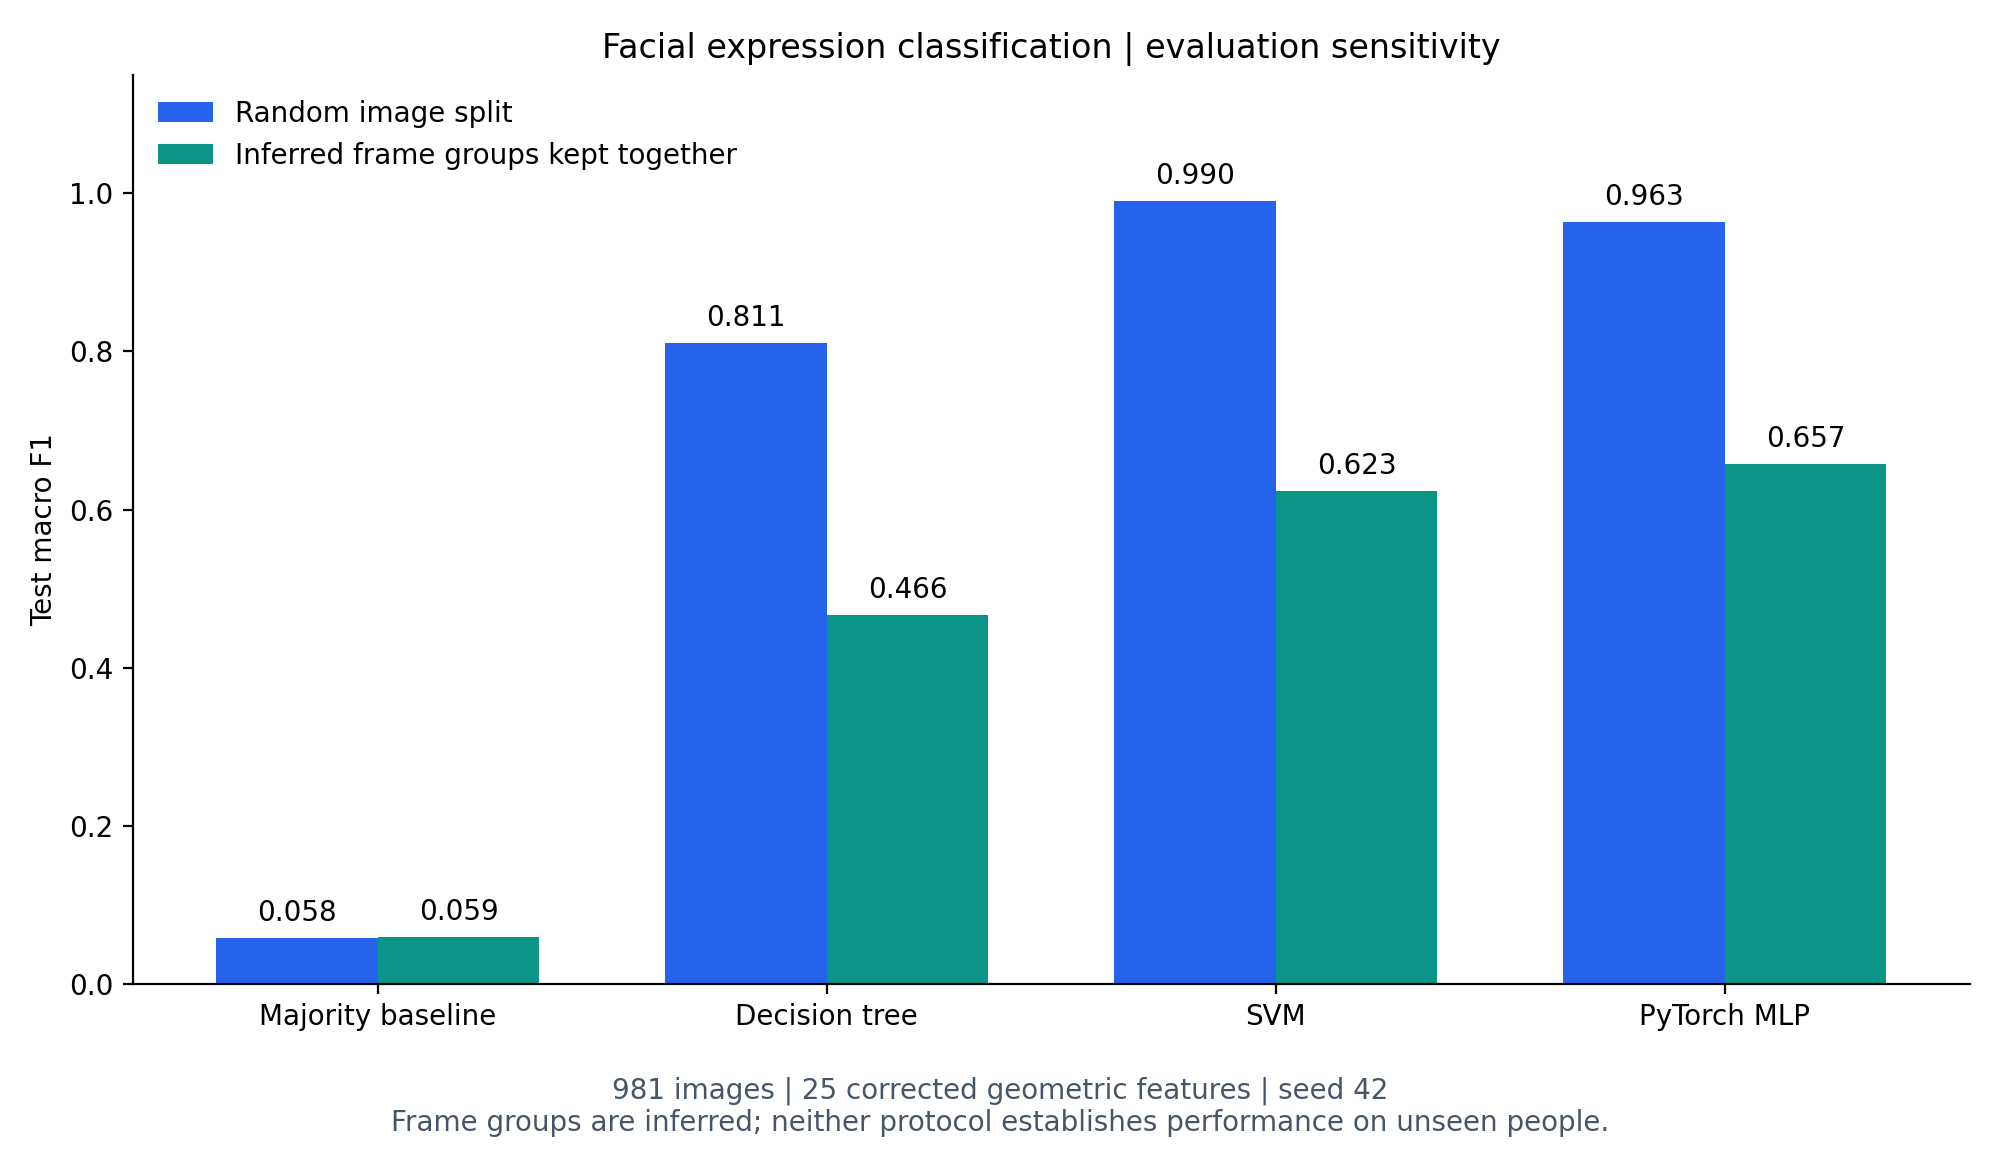

In [4]:
image = pd.read_csv(ROOT / "results/metrics.csv")
grouped = pd.read_csv(ROOT / "results/inferred_sequence/metrics.csv")
comparison = pd.concat([image.assign(protocol="Image split"), grouped.assign(protocol="Inferred groups")])
display(comparison.query("split == 'test'").pivot(index="model", columns="protocol", values="macro_f1").round(4))
display(Image(filename=str(ROOT / "results/evaluation_comparison.png")))

## Inspect errors and features

The charts use natural test distributions; validation permutation importance shows the drop in macro F1 after shuffling a feature. Importance describes this fitted model and dataset, not a causal relationship.

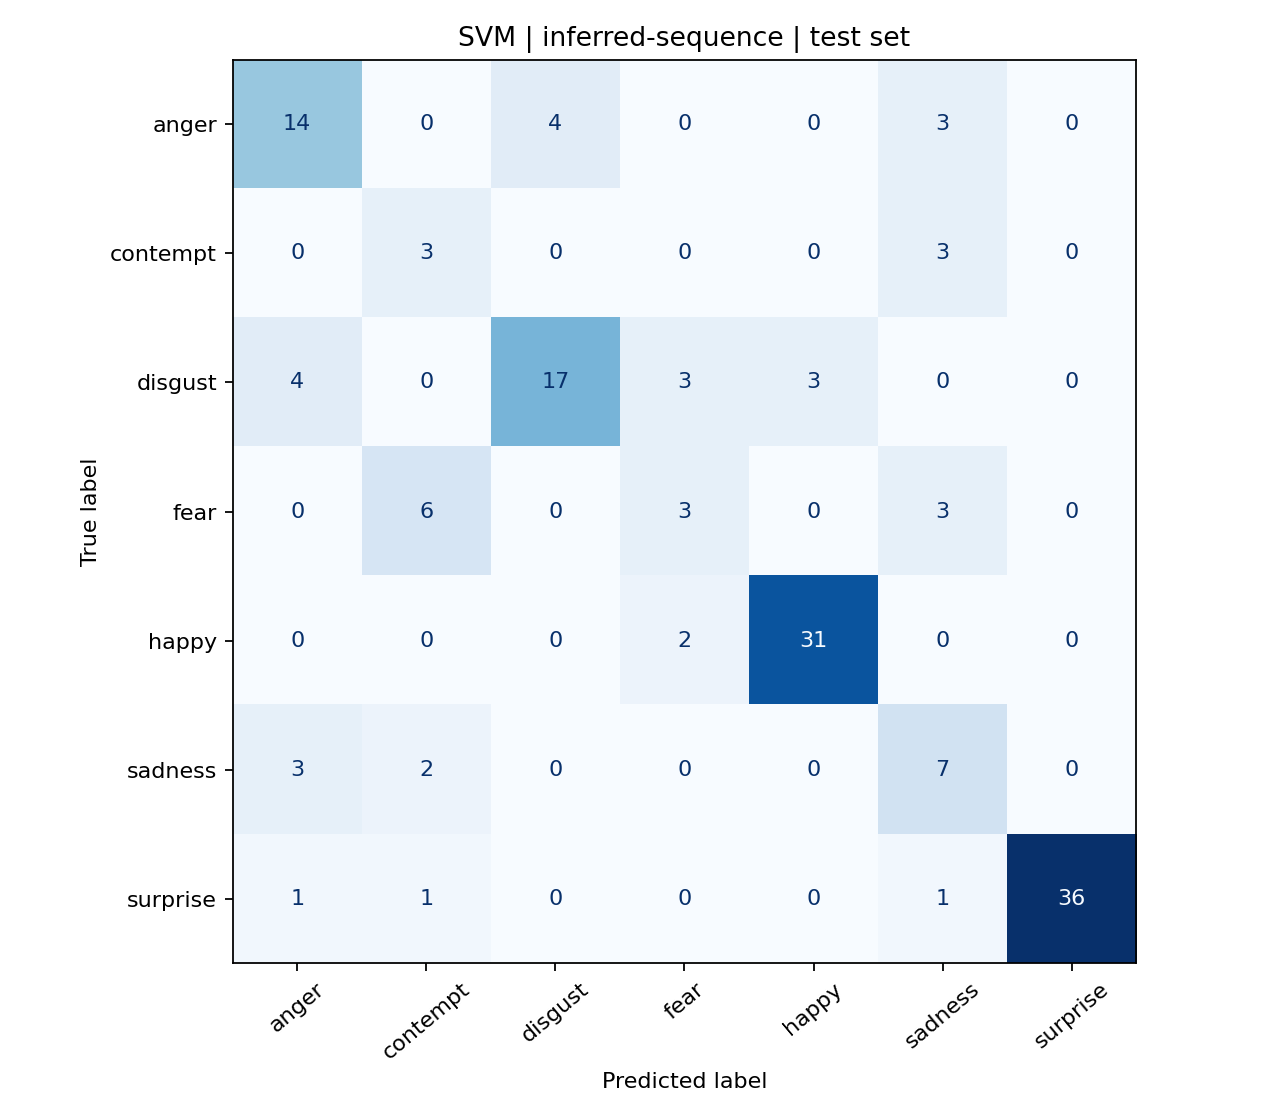

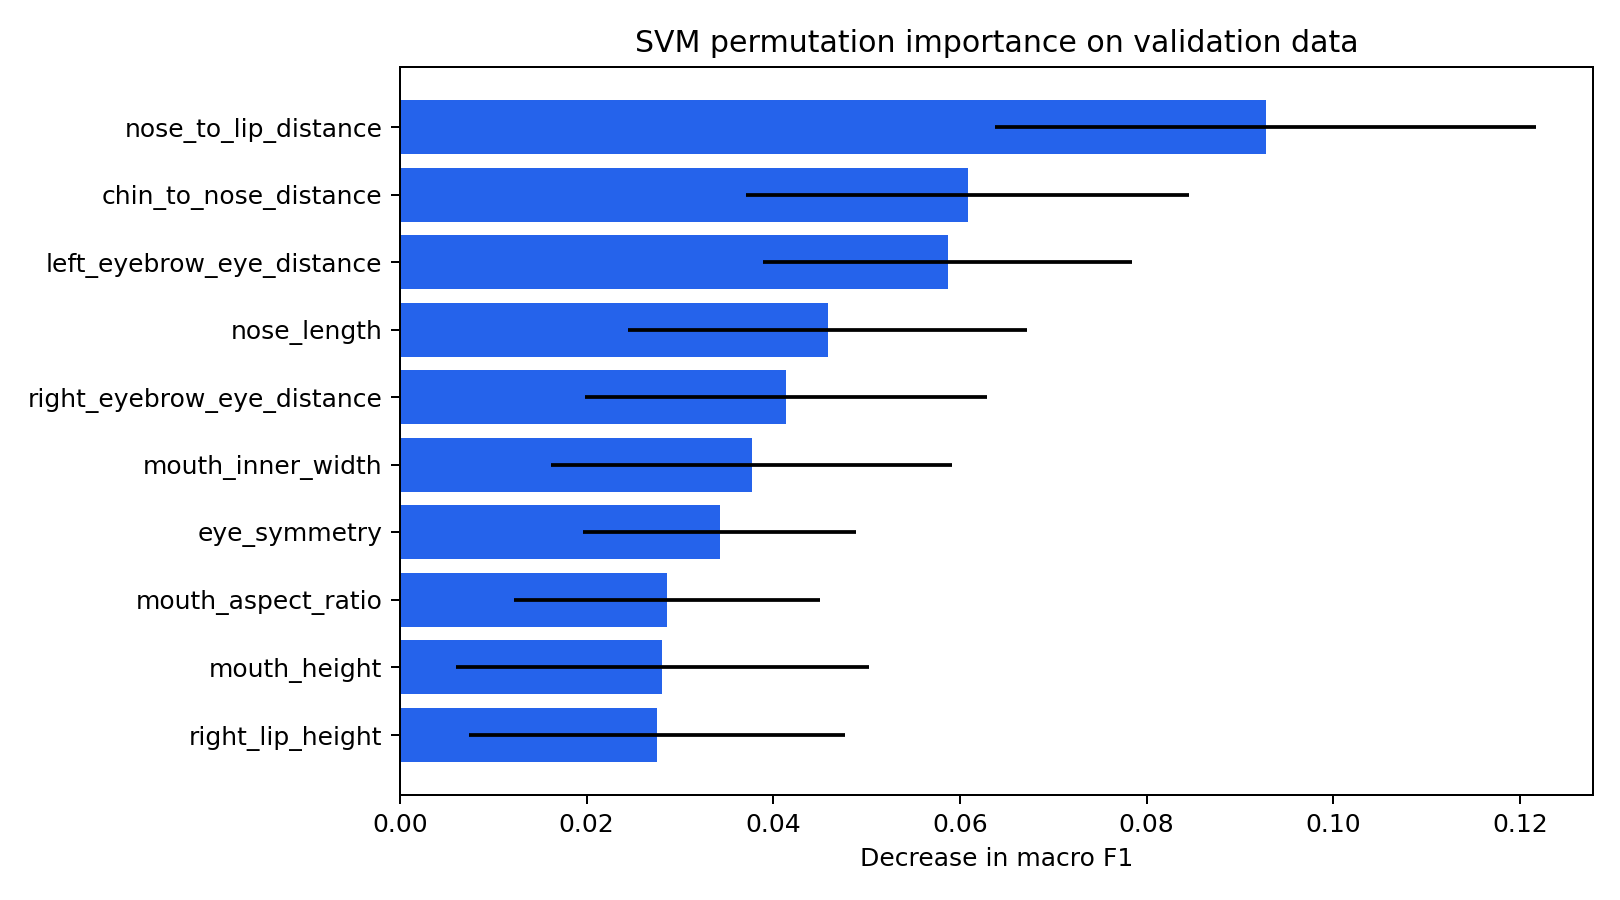

In [5]:
display(Image(filename=str(ROOT / "results/inferred_sequence/confusion_svm.png")))
display(Image(filename=str(ROOT / "results/inferred_sequence/feature_importance.png")))

## Interpretation

Image splitting shares likely related-frame groups across training and test. Keeping candidate groups together changes both the evaluation samples and model-selection protocol. Group identities are inferred from renamed filenames, so original subjects may still cross splits. A stronger next experiment requires original subject/sequence metadata and a fresh independent dataset.

See `../docs/results.md`, `../docs/data.md`, and `../docs/coursework.md` for the reproduced results, exact feature changes, and team contributions. The original coursework artifacts are preserved in `../archive/coursework/`.